# Praktikum Multilayer Perceptron (MLP)

**Mata Kuliah** : Kecerdasan Buatan  
**Nama** : Christina Adelia Sitinjak  
**NIM** : 42324056  
**Sumber modul** : Sesi 2 MLP, oleh Tegar Arifin Prasetyo

## Tujuan dan Gambaran Umum Praktikum

Praktikum ini membahas Multilayer Perceptron (MLP), yaitu salah satu jenis Neural Network yang tersusun dari beberapa lapisan neuron yang saling terhubung penuh. Pada praktikum Neural Network sebelumnya, tugas model adalah klasifikasi, yaitu menebak kategori seperti angka 0 sampai 9. Kali ini tugasnya adalah regresi, yaitu menebak sebuah angka yang nilainya bisa berapa saja. Studi kasusnya adalah memprediksi besar penjualan (`Sales`) berdasarkan anggaran iklan yang dikeluarkan di tiga media, yaitu TV, Radio, dan Newspaper (koran). Dengan kata lain, model menerima tiga angka sebagai input dan mengeluarkan satu angka sebagai prediksi penjualan.

Dataset yang dipakai adalah `advertising.csv` yang berisi 200 baris data. Setiap baris menggambarkan satu kasus pemasaran, dengan kolom `TV`, `Radio`, dan `Newspaper` sebagai besar anggaran iklan, serta kolom `Sales` sebagai penjualan yang dihasilkan. Data dibagi menjadi 80% data latih (160 baris) dan 20% data uji (40 baris), sehingga kemampuan model bisa diuji pada data yang tidak ikut dipakai untuk belajar.

Tahapan praktikum dimulai dari menyiapkan lingkungan dan library, memuat serta memeriksa data, membagi data, dan melihat pola data lewat grafik. Setelah itu dibangun sebuah MLP dengan tiga hidden layer, dilatih selama 1400 epoch, lalu dievaluasi. Terakhir, hasil prediksi model dibandingkan dengan nilai sebenarnya lewat grafik untuk tiap jenis media iklan.

Karena kasusnya regresi, ukuran kesalahan yang dipakai berbeda dari klasifikasi. Ukuran pertama adalah MSE (Mean Squared Error), yaitu rata-rata dari selisih prediksi dan nilai asli yang dikuadratkan, sehingga kesalahan besar dihukum lebih berat. Ukuran kedua adalah MAE (Mean Absolute Error), yaitu rata-rata selisih mutlak antara prediksi dan nilai asli, yang lebih mudah dibayangkan karena satuannya sama dengan `Sales`. Misalnya MAE 1,3 berarti rata-rata tebakan model meleset sekitar 1,3 satuan penjualan.

Seluruh kode dan output di bawah ini adalah milik modul asli yang dijalankan di Google Colab. Penjelasan saya tuliskan di bawah setiap cell, berisi maksud kode, cara kerjanya, dan arti dari hasil yang muncul.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#### Penjelasan:
Kode di atas untuk memanggil (import) semua library yang dibutuhkan pada praktikum ini. Library pandas (diberi nama pendek pd) dipakai untuk membaca dan mengolah data berbentuk tabel, numpy (np) untuk perhitungan angka dan array, matplotlib.pyplot (plt) untuk membuat grafik, dan tensorflow (tf) sebagai library utama untuk membangun dan melatih Neural Network.
Selain itu, dari library sklearn diambil dua alat, yaitu train_test_split untuk membagi data menjadi data latih dan data uji, serta StandardScaler untuk menyamakan skala angka (standarisasi). Perlu dicatat bahwa StandardScaler hanya diimpor dan tidak dipakai pada langkah-langkah berikutnya, sehingga data masuk ke model dengan skala aslinya. Karena cell ini hanya berisi perintah import, tidak ada output yang ditampilkan.

In [2]:
dataset = pd.read_csv('advertising.csv')
dataset.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [3]:
!pip install tensorflow


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


#### Penjelasan:
Perintah `!pip install tensorflow` memasang library TensorFlow. Tanda `!` di depannya membuat Colab menjalankannya sebagai perintah terminal, bukan kode Python. Output `Requirement already satisfied` menunjukkan bahwa TensorFlow sudah terpasang di Colab, dan versi yang tercatat adalah 2.17.0, jadi tidak ada yang diunduh ulang.

In [4]:
!pip install pandas matplotlib scikit-learn


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


#### Penjelasan:
Perintah ini memasang tiga library pendukung sekaligus, yaitu `pandas` untuk olah data, `matplotlib` untuk grafik, dan `scikit-learn` untuk pembagian data dan standarisasi. Sama seperti sebelumnya, semuanya sudah tersedia di Colab. Versi yang tercatat pada output adalah pandas 2.1.4, matplotlib 3.7.1, dan scikit-learn 1.3.2.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#### Penjelasan:
Cell ini isinya sama persis dengan cell import di bagian awal. Pengulangan seperti ini tidak berbahaya, hanya memastikan semua library sudah siap dipakai setelah proses pemasangan. Kalau mau lebih rapi, cukup satu kali import saja.

In [7]:
# Load dataset
dataset = pd.read_csv('advertising.csv')

# Lihat beberapa baris dataset
dataset.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


#### Penjelasan:
`pd.read_csv('/content/advertising.csv')` membaca file CSV lalu menyimpannya sebagai tabel (DataFrame) bernama `dataset`. Alamat `/content/` adalah folder kerja di Colab, jadi file `advertising.csv` harus diunggah ke sana terlebih dahulu. Perintah `dataset.head()` menampilkan 5 baris pertama untuk melihat gambaran isi data.

Dari output terlihat ada empat kolom. `TV`, `Radio`, dan `Newspaper` adalah besar anggaran iklan di masing-masing media, sedangkan `Sales` adalah penjualan yang dihasilkan. Contohnya pada baris pertama, anggaran TV 230,1, Radio 37,8, dan Newspaper 69,2 menghasilkan penjualan 22,1. Karena yang ingin ditebak (`Sales`) berupa angka kontinu, kasus ini adalah regresi.

In [8]:
dataset.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


#### Penjelasan:
`dataset.describe()` menampilkan ringkasan statistik dari tiap kolom. Dari hasilnya ada 200 data (`count`) di setiap kolom. Anggaran TV rata-ratanya 147,04 dengan rentang 0,7 sampai 296,4. Anggaran Radio rata-ratanya 23,26 dengan rentang 0 sampai 49,6, dan Newspaper rata-ratanya 30,55 dengan rentang 0,3 sampai 114. Penjualan (`Sales`) rata-ratanya 15,13, terkecil 1,6 dan terbesar 27.

Ada satu hal penting yang terlihat dari tabel ini, yaitu skala tiap kolom berbeda-beda. Anggaran TV bisa mencapai ratusan, sedangkan Radio paling besar hanya sekitar 50. Perbedaan skala seperti ini biasanya membuat Neural Network belajar kurang efisien, dan itulah fungsi `StandardScaler` yang sudah diimpor di awal. Pada notebook ini standarisasi tidak dilakukan, dan model tetap bisa belajar karena datanya masih cukup sederhana.

In [9]:
# Cek nilai null
dataset.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

#### Penjelasan:
`dataset.isnull().sum()` menghitung jumlah nilai kosong (null) pada tiap kolom. Hasilnya 0 untuk `TV`, `Radio`, `Newspaper`, dan `Sales`, artinya tidak ada data yang kosong. Pengecekan ini penting sebelum melatih model, karena nilai kosong bisa menyebabkan error atau hasil yang menyimpang. Karena datanya sudah lengkap, tidak ada proses pembersihan tambahan yang diperlukan.

In [10]:
# Split data menjadi training dan testing set
from sklearn.model_selection import train_test_split

X = dataset.drop(['Sales'], axis=1)
y = dataset['Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#### Penjelasan:
Cell ini memisahkan data menjadi fitur dan target, lalu membaginya menjadi data latih dan data uji. `X = dataset.drop(['Sales'], axis=1)` mengambil semua kolom kecuali `Sales`, yaitu `TV`, `Radio`, dan `Newspaper`, sebagai fitur atau input. `y = dataset['Sales']` mengambil kolom `Sales` sebagai target yang ingin diprediksi.

Lalu `train_test_split(X, y, test_size=0.2, random_state=42)` membagi data secara acak. Nilai `test_size=0.2` berarti 20% data (40 baris) menjadi data uji dan 80% (160 baris) menjadi data latih. Angka `random_state=42` membuat pembagian acaknya selalu sama setiap kali dijalankan, sehingga hasilnya bisa diulang. Hasilnya ada empat variabel, yaitu `X_train` dan `y_train` untuk belajar, serta `X_test` dan `y_test` untuk menguji. Jumlah data latih 160 ini juga terlihat nanti pada log pelatihan, yaitu 5 langkah per epoch (160 dibagi 32 data per langkah).

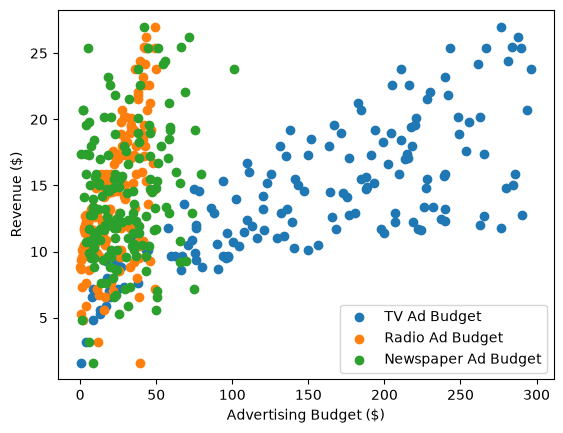

In [11]:
# Membuat plot dari dataset
plt.scatter(X_train['TV'], y_train, label='TV Ad Budget') # Changed column name to 'TV'
plt.scatter(X_train['Radio'], y_train, label='Radio Ad Budget') # Changed column name to 'Radio'
plt.scatter(X_train['Newspaper'], y_train, label='Newspaper Ad Budget') # Changed column name to 'Newspaper'
plt.xlabel('Advertising Budget ($)')
plt.ylabel('Revenue ($)')
plt.legend()
plt.show()

#### Penjelasan:
Cell ini membuat grafik sebaran (scatter plot) untuk melihat hubungan antara tiap jenis anggaran iklan dengan penjualan pada data latih. Tiga kali `plt.scatter(...)` menggambar tiga kumpulan titik dengan warna berbeda: sumbu x adalah anggaran iklan dan sumbu y adalah penjualan. Lalu `plt.xlabel`, `plt.ylabel`, dan `plt.legend` memberi nama sumbu dan keterangan warna, dan `plt.show()` menampilkannya. (Komentar di kode menyebut nama kolom diganti menjadi `TV`, `Radio`, dan `Newspaper`, sesuai nama kolom yang sebenarnya di dataset.)

Dari grafik, titik biru (TV) terlihat naik dari kiri bawah ke kanan atas. Semakin besar anggaran TV, penjualan cenderung semakin tinggi, jadi TV punya hubungan yang paling jelas dengan penjualan. Titik oranye (Radio) dan hijau (Newspaper) lebih menyebar, dan pola naiknya tidak setegas TV. Titik Newspaper terlihat paling acak. Ini baru kesan dari grafik, tetapi cukup memberi gambaran bahwa TV kemungkinan paling berpengaruh. Satu catatan kecil, sumbu y dilabeli `Revenue ($)` padahal datanya adalah kolom `Sales`.

In [12]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

# Membangun model MLP
model = Sequential([
    Dense(512, input_shape=(3,), activation='relu'),  # Input layer
    Dense(512, activation='relu'),  # Hidden layer 1
    Dense(256, activation='relu'),  # Hidden layer 2
    Dense(1)  # Output layer (tidak perlu fungsi aktivasi karena ini masalah regresi)
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

c:\Users\sitin_veptvir\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 396,289 (1.51 MB)

 Trainable params: 396,289 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

#### Penjelasan:
Di sinilah MLP dibangun. `Sequential` berarti layer-layernya disusun berurutan dari input ke output. Modelnya terdiri dari empat layer `Dense`, yaitu layer yang tiap neuronnya terhubung ke semua neuron di layer sebelumnya (inilah ciri "multilayer perceptron").

Layer pertama, `Dense(512, input_shape=(3,), activation='relu')`, berisi 512 neuron dan menerima 3 input (anggaran TV, Radio, Newspaper). Layer kedua, `Dense(512, activation='relu')`, adalah hidden layer 1 dengan 512 neuron. Layer ketiga, `Dense(256, activation='relu')`, adalah hidden layer 2 dengan 256 neuron. Fungsi aktivasi ReLU mengubah angka negatif menjadi 0 dan membiarkan angka positif, sehingga model bisa mempelajari hubungan yang tidak lurus. Layer keempat, `Dense(1)`, adalah output layer dengan satu neuron tanpa fungsi aktivasi. Keluarannya satu angka bebas, yaitu prediksi `Sales`. Tidak diberi aktivasi karena ini kasus regresi. Kalau diberi softmax seperti pada klasifikasi, hasilnya akan dibatasi menjadi probabilitas dan tidak cocok untuk menebak angka penjualan.

`model.compile(optimizer='adam', loss='mse', metrics=['mae'])` menentukan aturan belajar. Optimizer Adam menyesuaikan bobot model, `loss='mse'` berarti kesalahan yang diminimalkan adalah Mean Squared Error, dan `metrics=['mae']` menampilkan Mean Absolute Error supaya mudah dipantau.

Pada `model.summary()`, layer pertama punya 2.048 parameter (3 x 512 bobot ditambah 512 bias), layer kedua 262.656 (512 x 512 ditambah 512), layer ketiga 131.328 (512 x 256 ditambah 256), dan output layer 257 (256 x 1 ditambah 1). Totalnya 396.289 parameter. Peringatan `UserWarning` di output muncul karena Keras versi baru menyarankan memakai `Input(shape)` sebagai layer pertama, bukan `input_shape` di dalam `Dense`. Ini hanya peringatan, model tetap terbentuk dan berjalan normal. Perlu dicatat juga bahwa model ini cukup besar (sekitar 396 ribu parameter) untuk data yang hanya 160 baris.

In [13]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)
history = model.fit(X_train, y_train, epochs=1400, validation_data=(X_test, y_test))

Epoch 1/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 173.3379 - mae: 9.2751 - val_loss: 42.0587 - val_mae: 5.5417
Epoch 2/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 26.5506 - mae: 4.2048 - val_loss: 24.9922 - val_mae: 3.7328
Epoch 3/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 13.9109 - mae: 2.9124 - val_loss: 15.5836 - val_mae: 3.3563
Epoch 4/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 9.0524 - mae: 2.4415 - val_loss: 10.6365 - val_mae: 2.4229
Epoch 5/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 6.5585 - mae: 2.0457 - val_loss: 7.1321 - val_mae: 2.1108
Epoch 6/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 4.5553 - mae: 1.7224 - val_loss: 6.6486 - val_mae: 2.0626
Epoch 7/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 3.7621 - mae: 1.6037 - val_loss: 7.3116 - val_mae: 2.1694
Epoch 8/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 3.4612 - mae: 1.5039 - val_loss: 4.6716 - val_mae: 1.6637
Epoch 9/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - los

#### Penjelasan:
Cell ini melatih model. `model.fit(X_train, y_train, epochs=1400, validation_data=(X_test, y_test))` membuat model mempelajari 160 data latih sebanyak 1400 putaran (epoch). Setelah tiap epoch, model dicoba pada data uji (`validation_data`) supaya kelihatan apakah ia benar-benar belajar atau hanya menghafal. Hasil perkembangannya disimpan di `history` untuk dibuat grafik. Angka `5/5` di log artinya satu epoch terdiri dari 5 langkah (batch), karena 160 data dibagi 32 data per batch.

Baris pertama cell ini membuat `early_stop`, yaitu fitur untuk menghentikan pelatihan lebih awal jika `val_loss` tidak membaik selama 5 epoch berturut-turut. Namun `early_stop` tidak pernah dimasukkan ke `model.fit` lewat parameter `callbacks`, sehingga tidak berpengaruh. Itulah sebabnya log menunjukkan pelatihan berjalan penuh sampai `Epoch 1400/1400`.

Hasil log menunjukkan model belajar dengan cepat di awal. Pada epoch 1, `loss` masih 325,32 dan `val_mae` 9,29. Pada epoch 10, `val_mae` turun menjadi sekitar 1,99. Setelah itu penurunannya melambat, dengan `val_mae` sekitar 1,77 di epoch 100 dan sekitar 1,16 di epoch 300. Nilai `val_mae` terbaik adalah sekitar 1,00 pada epoch 880. Di epoch terakhir (1400), `loss` data latih 0,4656 dan `mae` 0,4783, sedangkan `val_loss` 2,8451 dan `val_mae` 1,2908.

Perhatikan bahwa kesalahan pada data latih (MAE sekitar 0,5 pada ratusan epoch terakhir) jauh lebih kecil dibanding data uji (sekitar 1,2). Selisih ini tanda awal overfitting, yaitu model mulai terlalu menyesuaikan diri dengan data latih. Nilai `val_loss` juga naik-turun dari epoch ke epoch, yang wajar karena data ujinya hanya 40 baris.

In [14]:
test_loss, test_mae = model.evaluate(X_test, y_test)
print(f"Mean Absolute Error pada data pengujian: {test_mae}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.6564 - mae: 0.5293
Mean Absolute Error pada data pengujian: 0.5292509198188782


#### Penjelasan:
`model.evaluate(X_test, y_test)` menguji model yang sudah selesai dilatih pada data uji, lalu mengembalikan dua nilai, yaitu `test_loss` (MSE) dan `test_mae`. Hasil yang dicetak adalah MAE sebesar 1,29. Artinya, rata-rata prediksi model meleset sekitar 1,29 satuan penjualan dari nilai sebenarnya. Karena rata-rata `Sales` adalah 15,13, kesalahan ini setara sekitar 8,5% dari rata-rata penjualan, sehingga modelnya cukup baik untuk model sederhana.

Angka ini sama dengan `val_mae` pada epoch 1400, karena data yang dipakai untuk validasi selama pelatihan dan untuk evaluasi akhir sebenarnya sama, yaitu `X_test` dan `y_test`. Konsekuensinya, hasil ini belum benar-benar "data baru" bagi proses pelatihan. Idealnya ada pembagian ketiga (data validasi terpisah dari data uji), tetapi untuk keperluan praktikum cara ini sudah cukup.

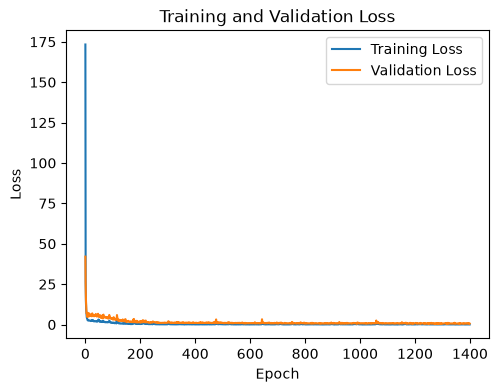

In [15]:
# Plot Loss dan MAE selama pelatihan
plt.figure(figsize=(12, 4))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()


#### Penjelasan:
Cell ini menggambar grafik perkembangan loss selama pelatihan. `plt.figure(figsize=(12, 4))` membuat kanvas lebar, lalu `plt.subplot(1, 2, 1)` menyiapkan grafik pertama dari rencana 1 baris dan 2 kolom. Garis biru (`Training Loss`) adalah kesalahan pada data latih dan garis oranye (`Validation Loss`) adalah kesalahan pada data uji, keduanya diambil dari `history.history` per epoch. Komentar pada kode menyebut grafik Loss dan MAE, tetapi yang digambar hanya grafik Loss, sehingga di sisi kanan kanvas tidak ada grafik kedua.

Pada grafik terlihat loss sangat tinggi di awal (di atas 250) lalu langsung jatuh drastis dalam beberapa epoch pertama. Sesudah itu kedua garis tampak hampir mendatar di dekat nol. Garis validation sedikit berada di atas garis training dan lebih bergelombang, sesuai dengan temuan sebelumnya. Karena nilai awalnya sangat besar, perubahan kecil setelahnya sulit terbaca. Kalau ingin lebih jelas, sumbu y bisa dibatasi, misalnya dengan `plt.ylim(0, 10)`, atau diganti skala logaritma.

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


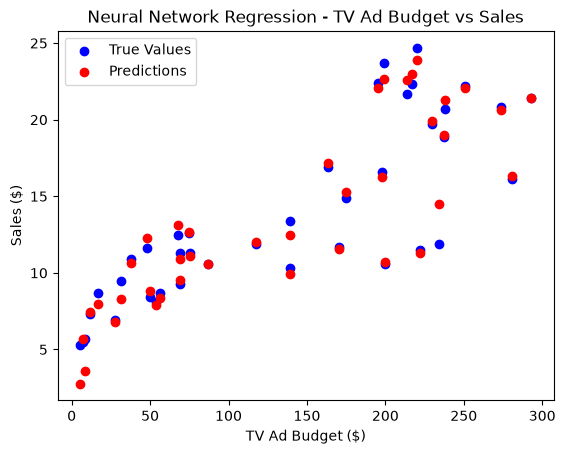

In [16]:
y_pred_test = model.predict(X_test)

plt.scatter(X_test['TV'], y_test, color='blue')

# Scatter plot of predictions (red)
plt.scatter(X_test['TV'], y_pred_test, color='red')

# Set the axis labels and title
plt.xlabel('TV Ad Budget ($)')
plt.ylabel('Sales ($)')
plt.title('Neural Network Regression - TV Ad Budget vs Sales')

# Add a legend to the plot
plt.legend(['True Values', 'Predictions'])
plt.show()

#### Penjelasan:
Cell ini membandingkan prediksi model dengan nilai asli. `model.predict(X_test)` membuat model menebak `Sales` untuk 40 data uji, dan hasilnya disimpan di `y_pred_test`. Lalu dua `plt.scatter` menggambar titik biru untuk nilai sebenarnya (`y_test`) dan titik merah untuk prediksi, dengan sumbu x berupa anggaran TV.

Pada grafik, titik merah berada sangat dekat dengan titik biru dan mengikuti pola naik yang sama. Semakin besar anggaran TV, semakin besar pula penjualan, baik pada nilai asli maupun prediksi. Pada anggaran TV rendah (di bawah 100) prediksi cukup dekat dengan nilai asli, dengan selisih umumnya hanya sekitar 1 sampai 2 satuan. Pada anggaran TV tinggi (di atas 200) selisihnya sedikit lebih besar, misalnya ada beberapa titik yang prediksinya lebih tinggi atau lebih rendah beberapa satuan dari nilai asli. Secara keseluruhan, grafik ini menunjukkan model berhasil menangkap hubungan antara anggaran TV dan penjualan.

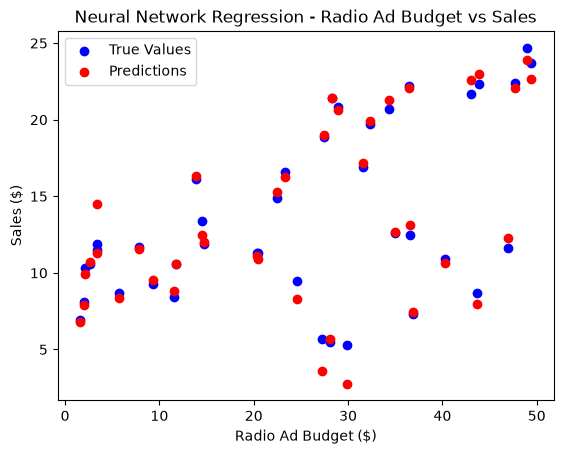

In [17]:
plt.scatter(X_test['Radio'], y_test, color='blue')

# Scatter plot of predictions (red)
plt.scatter(X_test['Radio'], y_pred_test, color='red')

# Set the axis labels and title
plt.xlabel('Radio Ad Budget ($)')
plt.ylabel('Sales ($)')
plt.title('Neural Network Regression - Radio Ad Budget vs Sales')

# Add a legend to the plot
plt.legend(['True Values', 'Predictions'])
plt.show()

#### Penjelasan:
Cell ini sama seperti sebelumnya, tetapi sumbu x diganti dengan anggaran Radio. Titik biru adalah nilai asli dan titik merah adalah prediksi model.

Pola pada grafik ini tidak serapi grafik TV, dan titik-titiknya tampak menyebar. Hal ini wajar. Model memprediksi penjualan memakai ketiga fitur sekaligus (TV, Radio, dan Newspaper), bukan hanya Radio. Jadi pada grafik yang hanya menampilkan satu fitur, dua titik dengan anggaran Radio yang mirip bisa mendapat prediksi yang berbeda karena anggaran TV dan Newspaper-nya berbeda. Yang perlu dilihat adalah kedekatan titik merah dengan titik biru di tiap posisi. Pada sebagian besar posisi, keduanya berdekatan, artinya prediksi model tetap mendekati nilai asli walaupun sebarannya tampak acak.

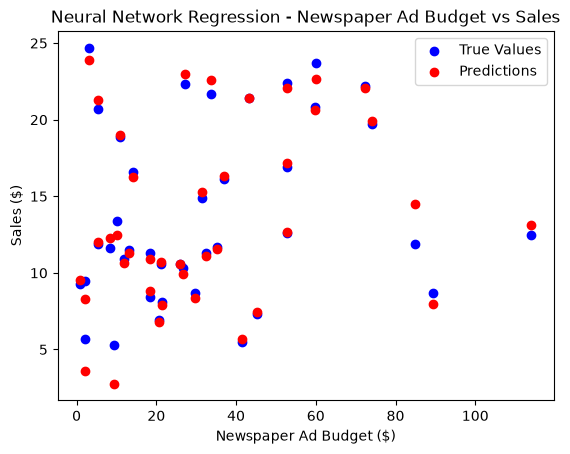

In [18]:
plt.scatter(X_test['Newspaper'], y_test, color='blue')

# Scatter plot of predictions (red)
plt.scatter(X_test['Newspaper'], y_pred_test, color='red')

# Set the axis labels and title
plt.xlabel('Newspaper Ad Budget ($)')
plt.ylabel('Sales ($)')
plt.title('Neural Network Regression - Newspaper Ad Budget vs Sales')

# Add a legend to the plot
plt.legend(['True Values', 'Predictions'])
plt.show()


#### Penjelasan:
Cell ini juga sama, dengan sumbu x berupa anggaran Newspaper. Hasilnya mirip dengan grafik Radio. Sebarannya tampak acak dan tidak membentuk garis yang jelas, tetapi titik merah (prediksi) tetap berada dekat titik biru (nilai asli) pada hampir semua posisi.

Dari ketiga grafik prediksi dapat disimpulkan bahwa MLP berhasil mempelajari hubungan antara kombinasi anggaran iklan dan penjualan. Kontribusi terbesar tampaknya berasal dari TV, karena hanya TV yang menunjukkan pola naik yang jelas bila dilihat sendiri. Radio dan Newspaper tampak berpengaruh lebih kecil bila dilihat satu per satu. Kesimpulan ini berdasarkan pengamatan grafik, bukan pengukuran pengaruh fitur secara khusus.

**Tugas** <br>

Silahkan jelaskan secara rinci kode program dan hasilnya (hint: lihat slide sesi teori ada gambaran secara umum, di tugas ini kalian detailkan maksud dan tujuannya), dikumpulkan paling lambat Rabu, 11 November 2026 jam 23.59 di ecourse

## Kesimpulan

Pada praktikum ini sebuah MLP dengan tiga hidden layer (512, 512, dan 256 neuron) berhasil dibuat untuk memprediksi penjualan dari anggaran iklan TV, Radio, dan Newspaper pada dataset yang berisi 200 data. Data dibagi menjadi 160 data latih dan 40 data uji, lalu model dilatih selama 1400 epoch memakai optimizer Adam dengan loss MSE. Hasil akhirnya, MAE pada data uji adalah sekitar 1,29, yang berarti rata-rata tebakan meleset sekitar 1,29 satuan penjualan, atau sekitar 8,5% dari rata-rata penjualan.

Dari grafik, TV adalah media yang paling jelas hubungannya dengan penjualan, dan prediksi model mengikuti nilai asli dengan cukup baik pada ketiga grafik perbandingan. Walaupun begitu ada beberapa hal yang bisa diperbaiki. Pertama, `StandardScaler` sudah diimpor tetapi tidak dipakai, padahal skala fitur berbeda-beda. Kedua, `early_stop` sudah dibuat tetapi tidak dimasukkan ke `model.fit`, sehingga pelatihan berjalan penuh 1400 epoch walaupun nilai `val_mae` terbaik sudah tercapai di sekitar epoch 880. Ketiga, kesalahan pada data latih (sekitar 0,5) jauh lebih kecil daripada data uji (sekitar 1,2 sampai 1,3), yang menunjukkan tanda awal overfitting karena model cukup besar untuk data yang hanya 160 baris. Keempat, data uji dipakai juga sebagai data validasi, sehingga hasil evaluasinya belum sepenuhnya independen.

Dari praktikum ini saya belajar perbedaan regresi dan klasifikasi pada Neural Network. Regresi memakai output layer satu neuron tanpa aktivasi dan loss seperti MSE, sedangkan klasifikasi memakai softmax dan loss crossentropy. Saya juga belajar membaca log pelatihan dan grafik loss untuk menilai apakah model sudah belajar dengan baik atau mulai overfitting.